In [3]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path


data_dir = Path("data")
if not data_dir.exists():
    data_dir = Path("..") / "data"

c1_train = pd.read_csv(data_dir / "case1" / "train1.csv")
c1_test = pd.read_csv(data_dir / "case1" / "test1.csv")
c2_train = pd.read_csv(data_dir / "case2" / "train2.csv")
c2_test = pd.read_csv(data_dir / "case2" / "test2.csv")

In [15]:
dfs = [c1_train, c1_test, c2_train, c2_test]

for df in dfs:
    # Convert RPM to kRPM
    df["speed_krpm"] = df["speed_rpm"] / 1000

    # Create differential pressure
    df["delta_p"] = df["outlet_pressure_bar"] - df["inlet_pressure_bar"]

    # Drop old columns
    df.drop(
        columns=["speed_rpm", "inlet_pressure_bar", "outlet_pressure_bar"],
        inplace=True
    )

In [16]:
c1_train

,pump_id,elapsed_s,operating_state,power_w,flow_m3_h,speed_krpm,delta_p
0,99223468_model_01,14.5,stable,669.992714,0.652884,4.230396,1.357291
1,99223468_model_01,24.5,stable,931.528480,43.040564,3.796520,0.293043
2,99223468_model_01,34.5,stable,724.198083,40.939560,3.508264,0.185766
3,99223468_model_01,44.5,stable,99.463217,11.857951,1.498405,0.163881
4,99223468_model_01,64.5,stable,608.195308,36.000996,3.224874,0.231682
...,...,...,...,...,...,...,...
475,99223468_model_01,5944.5,stable,815.229829,3.032111,4.376002,1.462426
476,99223468_model_01,5964.5,stable,515.961500,5.566221,3.514587,0.927272
477,99223468_model_01,5974.5,stable,534.173942,22.873572,2.935130,0.499988
478,99223468_model_01,5984.5,stable,154.677482,3.776250,2.214153,0.378757


In [20]:
all_data = pd.concat([c1_train, c1_test, c2_train, c2_test])

all_data[["speed_krpm", "delta_p", "power_w", "flow_m3_h"]].describe()

,speed_krpm,delta_p,power_w,flow_m3_h
count,180450.000000,180450.000000,180450.000000,180450.000000
mean,2.504052,0.436368,314.401809,12.530099
std,0.825111,0.298923,256.677122,8.374278
min,0.987144,-0.196580,21.285478,0.019673
25%,1.811114,0.192545,107.661220,5.994054
50%,2.506114,0.372484,236.944568,11.005568
75%,3.193103,0.633409,456.853764,17.748935
max,4.813199,1.764468,2201.655665,56.823209


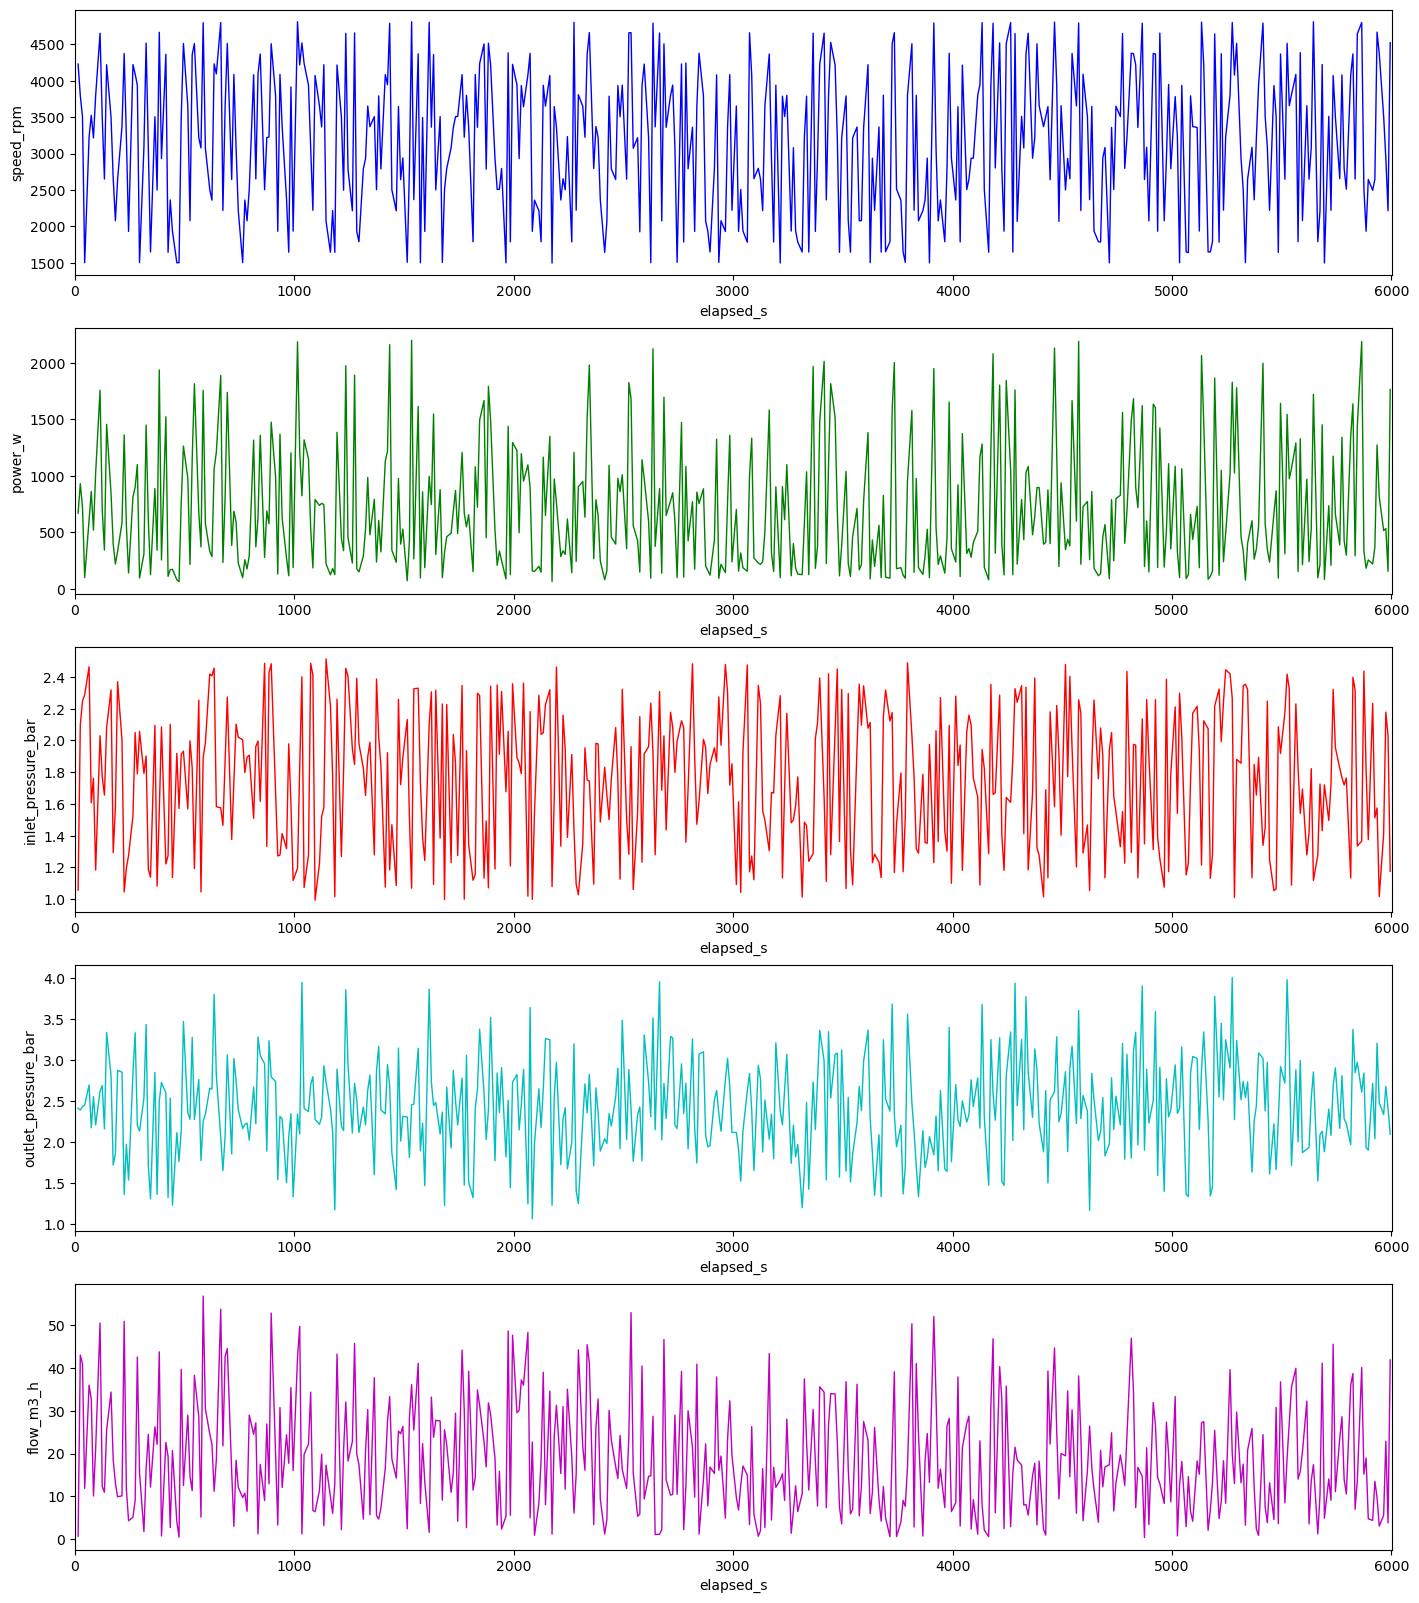

In [9]:
fig, axes = plt.subplots(5, 1, figsize=[17,20])
colors=['b','g','r','c', 'm']

for i, ax in enumerate(axes):
    ax.plot(c1_train["elapsed_s"],c1_train.iloc[:, [i+3]], linewidth=1, color=colors[i])
    ax.set_xlim(left=0, right=(c1_train["elapsed_s"].max()+10))
    ax.set_ylabel(c1_train.columns[i+3])
    ax.set_xlabel('elapsed_s')

plt.show()

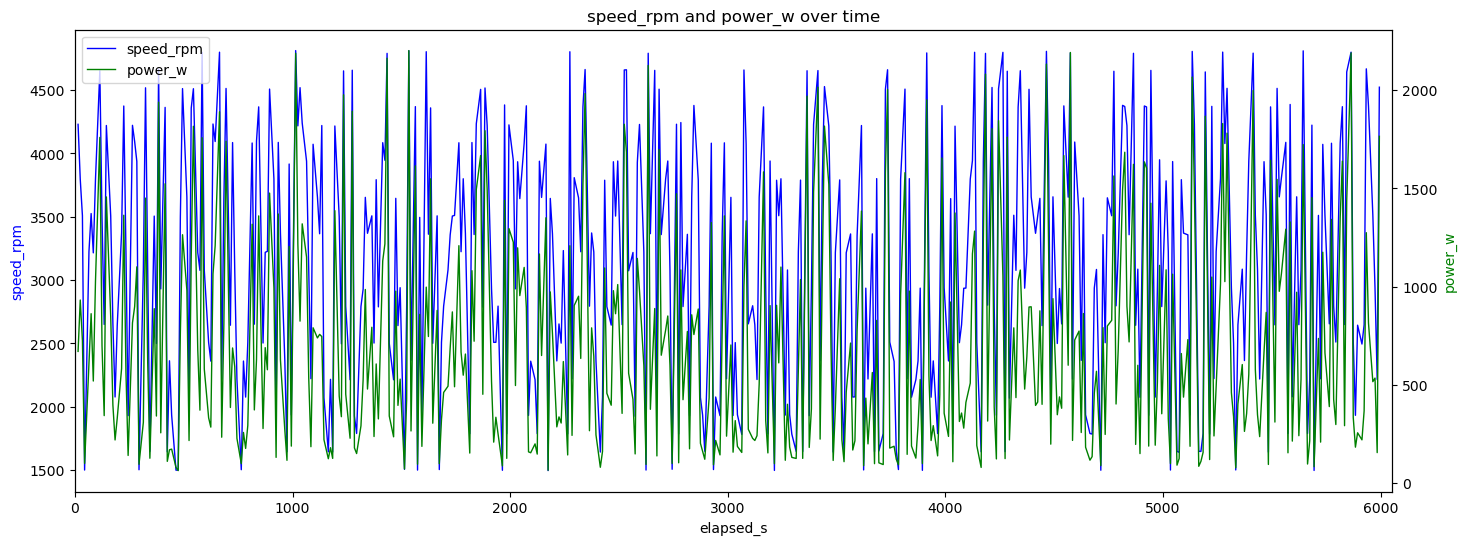

In [12]:
feature_1 = "speed_rpm"
feature_2 = "power_w"
plot_df = c1_train.sort_values("elapsed_s")

fig, ax1 = plt.subplots(figsize=(17, 6))

line_1, = ax1.plot(plot_df["elapsed_s"], plot_df[feature_1], linewidth=1, color="b", label=feature_1)
line_2, = ax1.plot(plot_df["elapsed_s"], plot_df[feature_2], linewidth=1, color="g", label=feature_2)

ax1.set_xlim(left=0, right=plot_df["elapsed_s"].max() + 60)
ax1.set_xlabel("elapsed_s")
ax1.set_ylabel(f"{feature_1} / {feature_2}")
ax1.set_title(f"{feature_1} and {feature_2} over time")
ax1.legend([line_1, line_2], [feature_1, feature_2], loc="upper left")

plt.show()

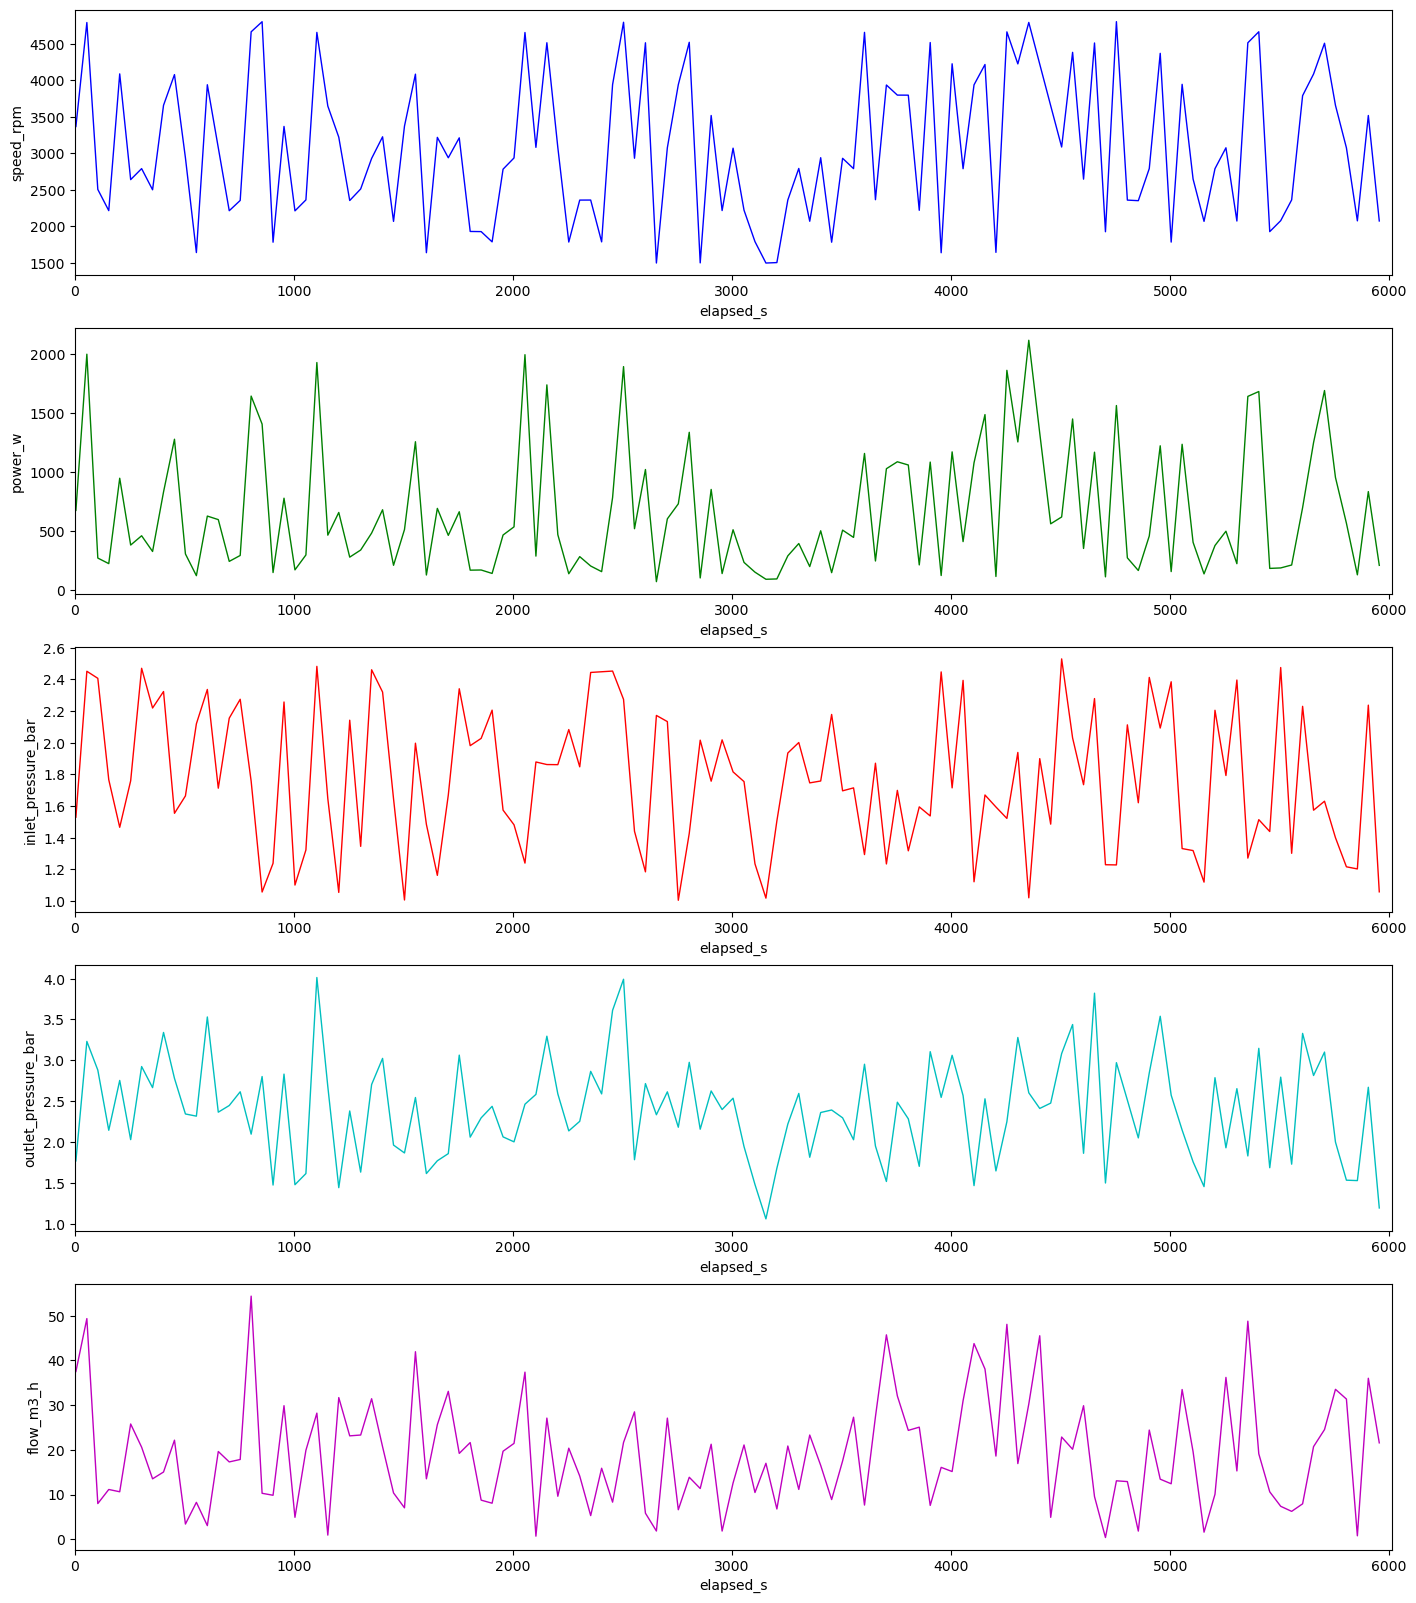

In [ ]:
fig, axes = plt.subplots(5, 1, figsize=[17,20])
colors=['b','g','r','c', 'm']

for i, ax in enumerate(axes):
    ax.plot(c1_test["elapsed_s"],c1_test.iloc[:, [i+3]], linewidth=1, color=colors[i])
    ax.set_xlim(left=0, right=(c1_test["elapsed_s"].max()+60))
    ax.set_ylabel(c1_test.columns[i+3])
    ax.set_xlabel('elapsed_s')

plt.show()

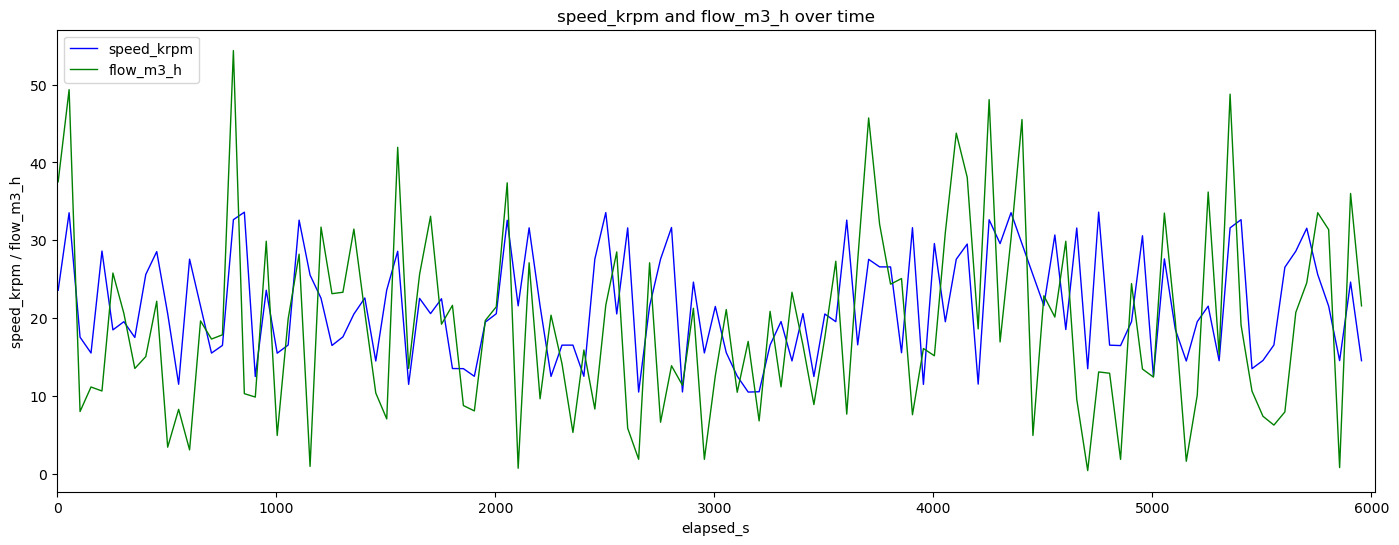

In [24]:
feature_1 = "speed_krpm"
feature_2 = "flow_m3_h"
plot_df = c1_test.sort_values("elapsed_s")

fig, ax1 = plt.subplots(figsize=(17, 6))

line_1, = ax1.plot(plot_df["elapsed_s"], plot_df[feature_1]*7, linewidth=1, color="b", label=feature_1)
line_2, = ax1.plot(plot_df["elapsed_s"], plot_df[feature_2], linewidth=1, color="g", label=feature_2)

ax1.set_xlim(left=0, right=plot_df["elapsed_s"].max() + 60)
ax1.set_xlabel("elapsed_s")
ax1.set_ylabel(f"{feature_1} / {feature_2}")
ax1.set_title(f"{feature_1} and {feature_2} over time")
ax1.legend([line_1, line_2], [feature_1, feature_2], loc="upper left")

plt.show()

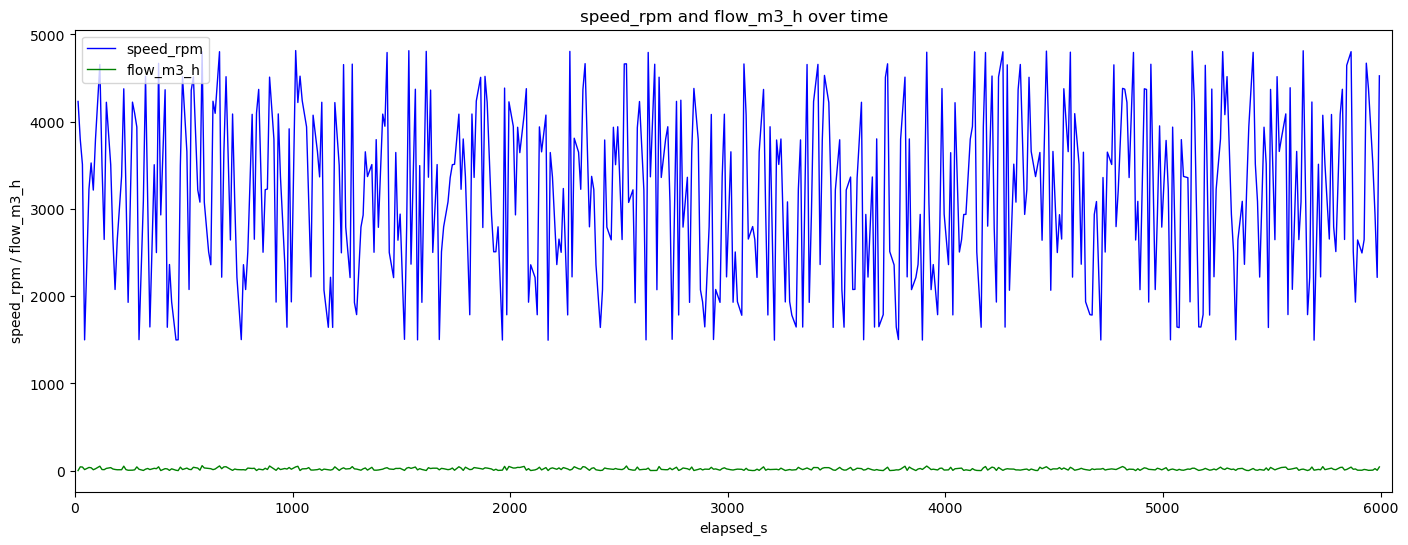

In [14]:
feature_1 = "speed_rpm"
feature_2 = "flow_m3_h"
plot_df = c1_train.sort_values("elapsed_s")

fig, ax1 = plt.subplots(figsize=(17, 6))

line_1, = ax1.plot(plot_df["elapsed_s"], plot_df[feature_1], linewidth=1, color="b", label=feature_1)
line_2, = ax1.plot(plot_df["elapsed_s"], plot_df[feature_2], linewidth=1, color="g", label=feature_2)

ax1.set_xlim(left=0, right=plot_df["elapsed_s"].max() + 60)
ax1.set_xlabel("elapsed_s")
ax1.set_ylabel(f"{feature_1} / {feature_2}")
ax1.set_title(f"{feature_1} and {feature_2} over time")
ax1.legend([line_1, line_2], [feature_1, feature_2], loc="upper left")

plt.show()

/var/folders/yc/hj112b594w727n5n4pblx23m0000gn/T/ipykernel_62606/2172485477.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


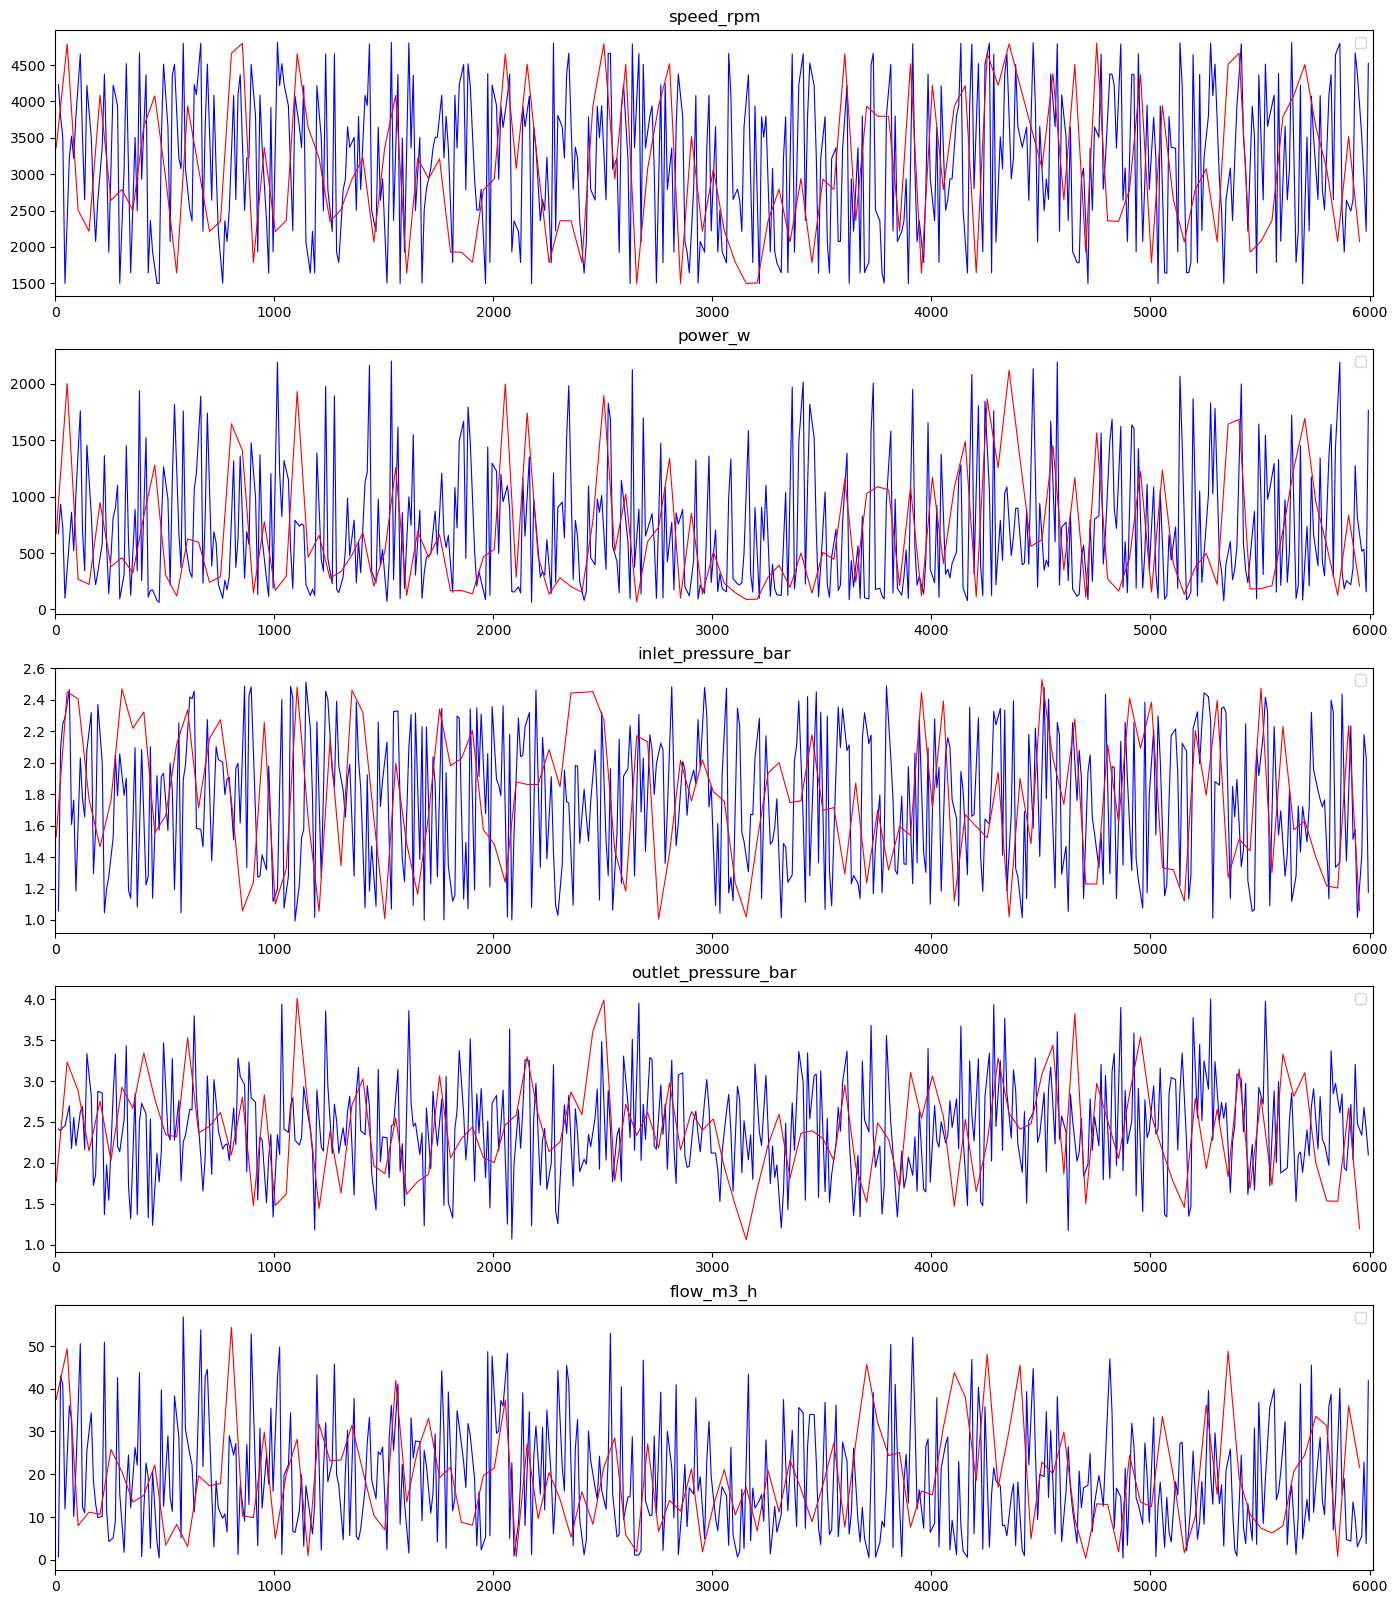

In [40]:
fig, axes = plt.subplots(5, 1, figsize=[17,20])

for i, ax in enumerate(axes):
    ax.plot(c1_train["elapsed_s"],c1_train.iloc[:, [i+3]], linewidth=0.8, color='b')
    ax.plot(c1_test["elapsed_s"],c1_test.iloc[:, [i+3]], linewidth=0.8, color='r')
    ax.set_xlim(left=0, right=(c1_test["elapsed_s"].max()+60))
    ax.set_title(c1_test.columns[i+3])
    ax.legend()

plt.show()

In [ ]:
groups=c2_train.groupby(["pump_id"])


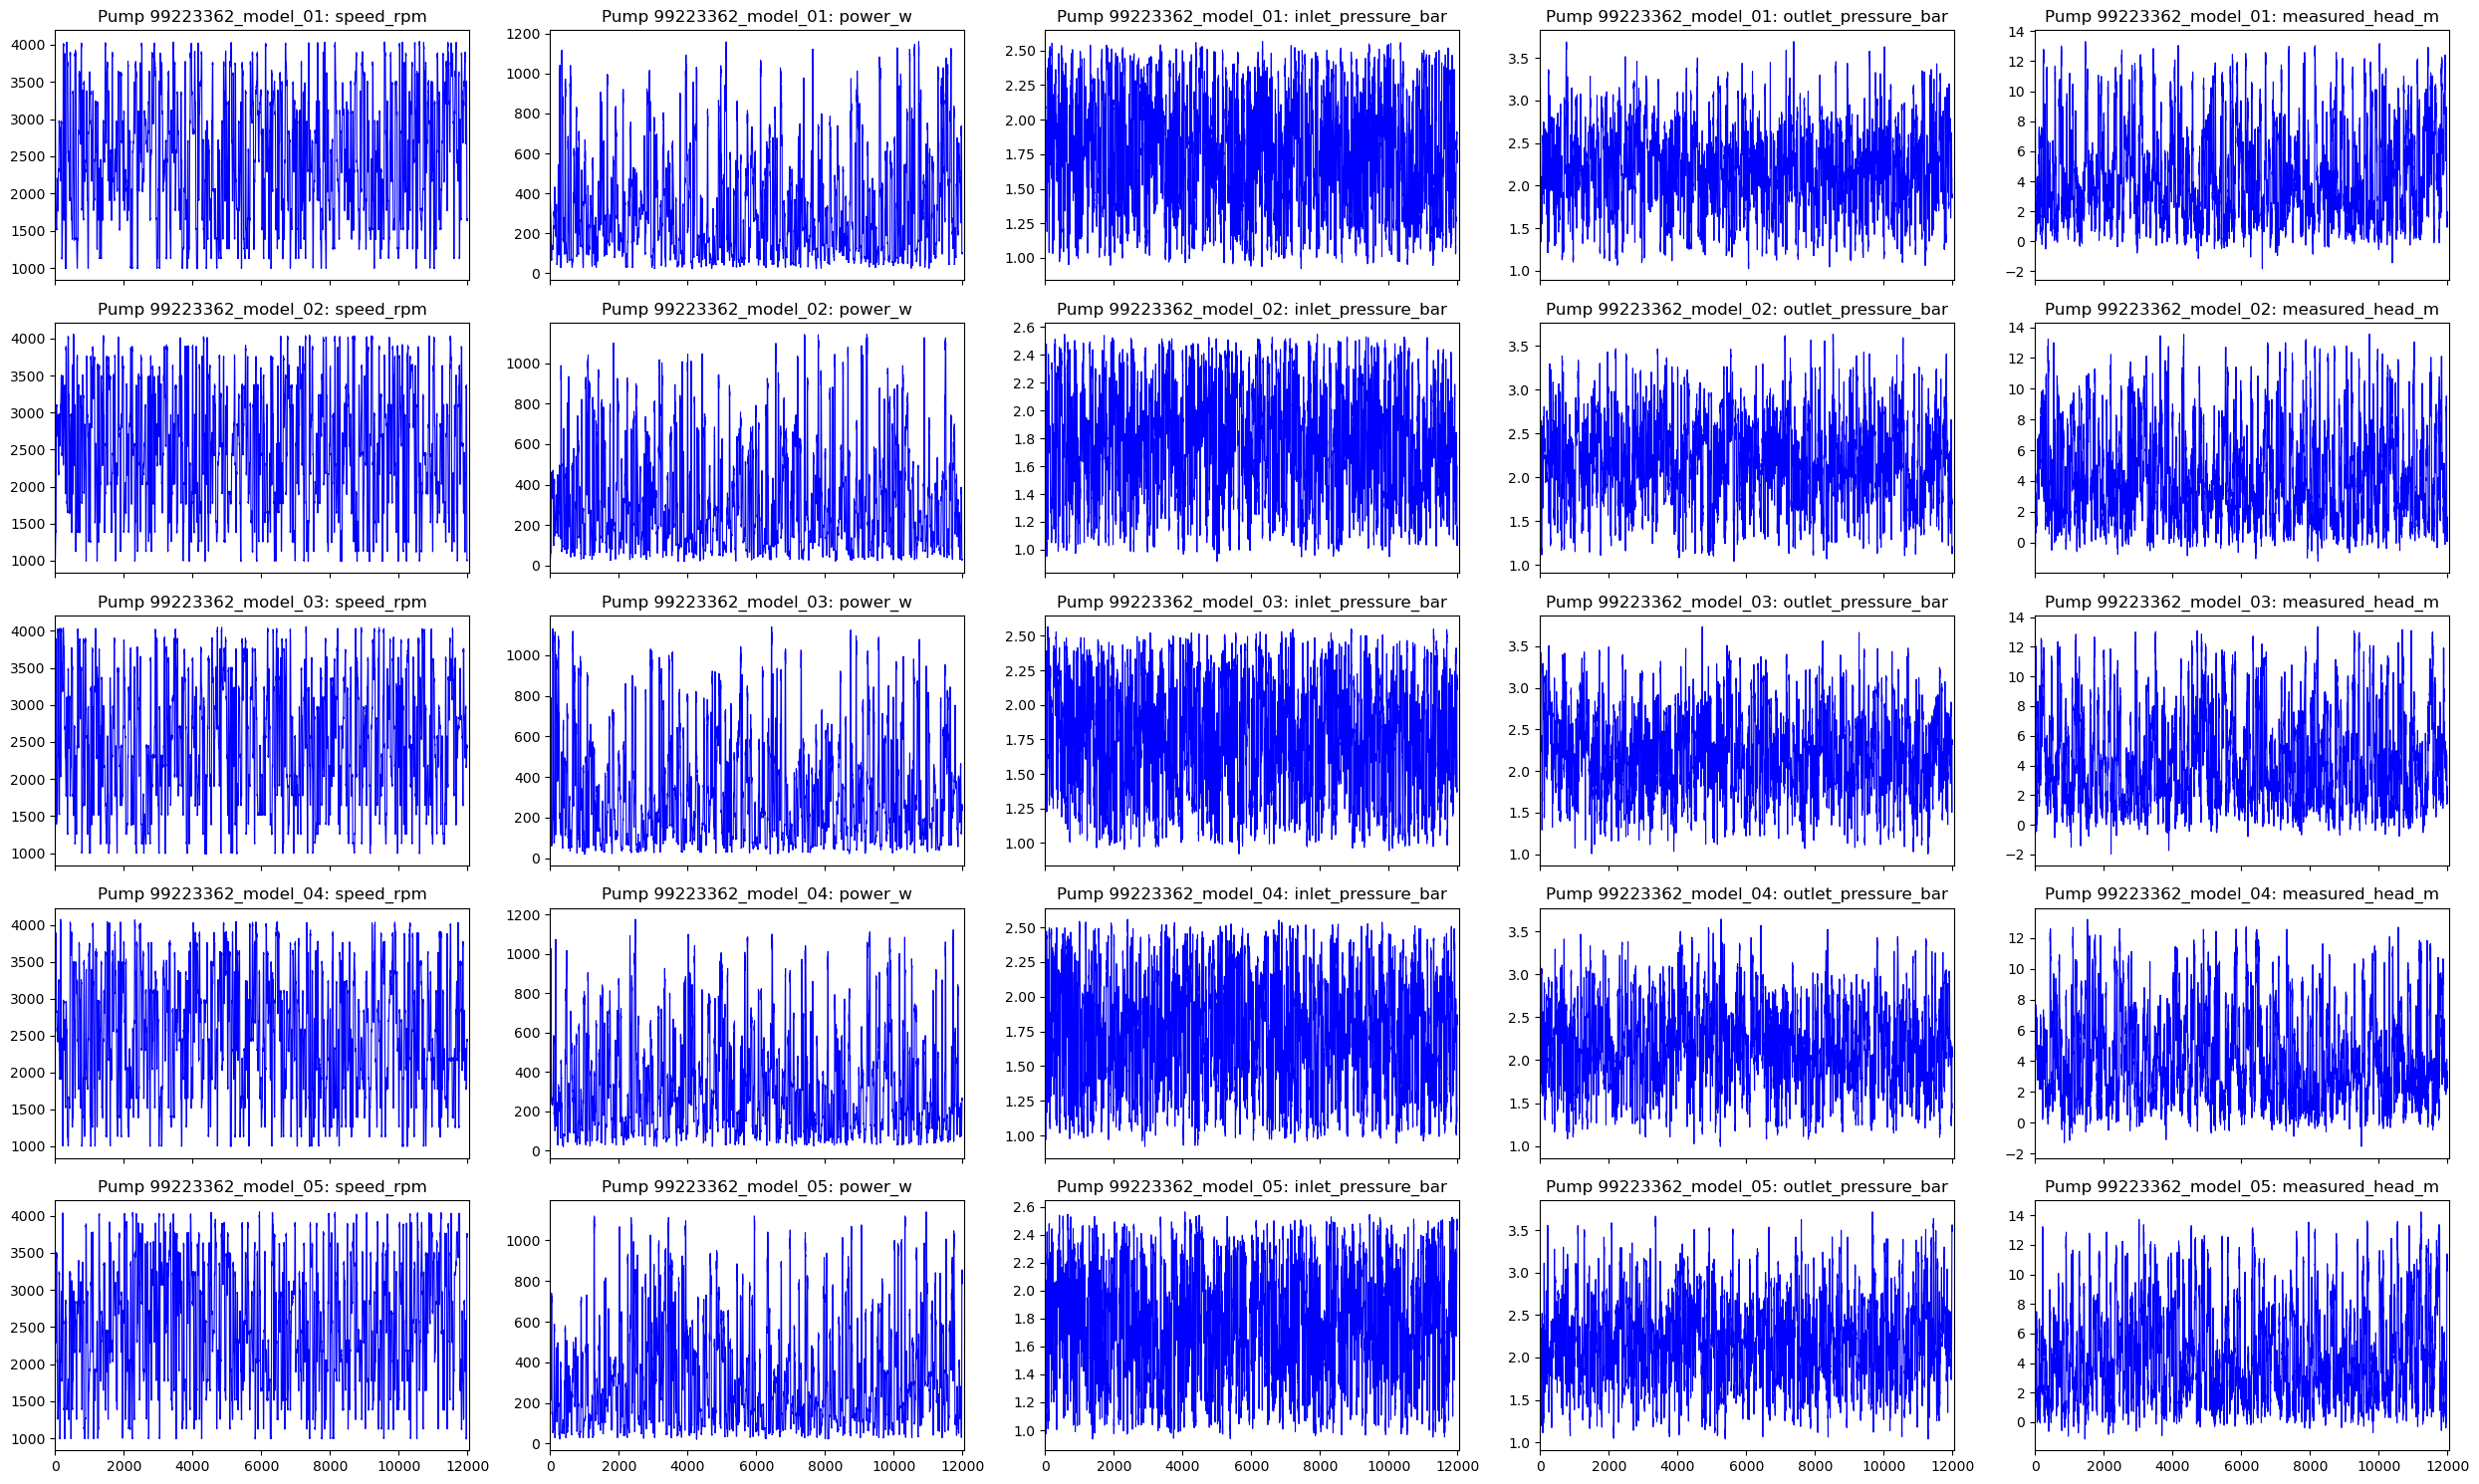

In [51]:
groups = c2_train.groupby("pump_id")
features = c2_train.columns[3:8]          # the 5 features

fig, axes = plt.subplots(5, 5, figsize=(25, 15), sharex=True)

for row, (pump, pump_df) in enumerate(groups):
    for col, feat in enumerate(features):
        ax = axes[row, col]
        ax.plot(pump_df["elapsed_s"], pump_df[feat], linewidth=0.8, color='b')
        ax.set_title(f"Pump {pump}: {feat}")

axes[0, 0].set_xlim(left=0, right=c2_train["elapsed_s"].max() + 60)
plt.tight_layout()
plt.show()